# Jaipur Junction-Informed Railway Platform Allocation — Benchmark v3

**Comparison:** Exact Classical Constrained Search vs Classical Simulated Annealing (SA) vs Simulated Quantum Annealing (SQA).

This version is a methodological correction to v2. It preserves the historically calibrated synthetic benchmark, but strengthens scenario diagnostics, exact-solver reuse, penalty calibration, annealing-effort tests, and result reporting.

## Scope and interpretation

- Historical context: six candidate platform resources and 28 trains in the historical busiest six-hour block. The historical report gives inconsistent counts (four vs five) for long-train-capable platforms; both are treated as sensitivity cases.
- Train-level times, nominal assignments, coach counts and delays are synthetic. This is **not** a reconstruction of Jaipur's current working timetable, station yard, signalling or interlocking.
- Platform IDs `P0`–`P5` are abstract. The first four or five are assumed long-train-capable for the respective sensitivity case; their real identities are not established here.
- Five minutes of clearance is a modelling assumption, not a verified Jaipur operating rule.

## What v3 changes

1. Runs one exact search per generated dataset, not once per solver repeat.
2. Separates three delay severities and classifies each dataset from the exact result: no reassignment needed, reassignment-required but feasible, infeasible, or unresolved timeout.
3. Verifies the QUBO energy (including offset) against the direct mathematical expression on random binary assignments.
4. Uses a transparent sufficient penalty bound `lambda > N` when a feasible assignment exists, then tests lower and higher values empirically.
5. Tests stronger annealing effort on the same calibration instance.
6. Reports per-dataset feasibility separately from per-read feasibility, and reports optimality hits only where exact search proves optimality.

**Important:** scenario classes are observed outcomes, not preselected labels. All generated pilot instances are retained, including infeasible cases. No instance is silently discarded to make the results look harder or easier.

In [1]:
%pip install -q openjij numpy pandas matplotlib psutil

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, platform, time, itertools, math, json, os, random
from pathlib import Path
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import openjij as oj
except ImportError as exc:
    raise ImportError("OpenJij is required. Run the installation cell, then restart the kernel.") from exc

try:
    import psutil
    RAM_GB = round(psutil.virtual_memory().total / 1024**3, 2)
except Exception:
    RAM_GB = None

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("CPU:", platform.processor() or "not exposed")
print("RAM (GB):", RAM_GB if RAM_GB is not None else "not measured")
print("OpenJij:", getattr(oj, "__version__", "version not exposed"))
try:
    import torch
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))
except Exception:
    print("PyTorch/CUDA: not installed; OpenJij SA/SQA in this notebook are CPU samplers.")

Python: 3.12.12
Platform: Windows-11-10.0.26300-SP0
CPU: Intel64 Family 6 Model 143 Stepping 8, GenuineIntel
RAM (GB): 127.65
OpenJij: version not exposed
PyTorch/CUDA: not installed; OpenJij SA/SQA in this notebook are CPU samplers.


## 1. Experimental configuration

The default run is a small calibration pilot: 8, 10 and 12 trains; delay maxima of 5, 10 and 15 minutes; three dataset seeds; and two independent sampler repeats. The exact solver is run once per dataset, while SA/SQA are repeated on the same dataset.

Do not turn on the 28-train benchmark until the small-instance diagnostics and calibration results have been reviewed.

In [3]:
# Historical-profile assumptions
N_PLATFORMS = 6
PEAK_WINDOW_START = 12 * 60
PEAK_WINDOW_END = 18 * 60
BASE_CLEARANCE_MIN = 5
LONG_TRAIN_COACH_THRESHOLD = 24
LONG_PLATFORM_COUNTS = (4, 5)

# Calibration pilot defaults
TRAIN_COUNTS = [8, 10, 12]
DELAY_LEVELS_MIN = [5, 10, 15]
DATASET_SEEDS = [11, 22, 33]
SOLVER_REPEATS = 2
NUM_READS = 100
NUM_SWEEPS = 500
EXACT_TIME_LIMIT_S = 30

# Sensitivity experiments (run on one exact-feasible calibration instance)
RUN_PENALTY_SENSITIVITY = True
RUN_EFFORT_SENSITIVITY = True
CALIBRATION_REPEATS = 2
CALIBRATION_READS = 200
CALIBRATION_SWEEPS = 1000
EFFORT_CONFIGS = [(100, 500), (300, 1000), (500, 2000)]

# Keep the actual Jaipur-profile size disabled until calibration has been reviewed.
RUN_28_TRAIN_BENCHMARK = False
RUN_CAPACITY_SENSITIVITY = False

# Scenario-level seed keys and solver seeds are deterministic and recorded.
print("Pilot datasets:", len(TRAIN_COUNTS) * len(DELAY_LEVELS_MIN) * len(DATASET_SEEDS))
print("Sampler runs expected:", len(TRAIN_COUNTS) * len(DELAY_LEVELS_MIN) * len(DATASET_SEEDS) * SOLVER_REPEATS * 2)
print("Safe sufficient penalty for N trains:", "lambda > N, if a feasible assignment exists")

Pilot datasets: 27
Sampler runs expected: 108
Safe sufficient penalty for N trains: lambda > N, if a feasible assignment exists


## 2. Synthetic scenario generator

The nominal schedule is built without same-platform overlap after clearance and spread across the six-hour window. The synthetic schedule generator uses adjacent service pairs (short gaps) separated by larger inter-pair gaps; this is an explicit schedule-shape assumption, not a claim about Jaipur's actual timetable. Independent non-negative delays shift arrival and departure together, preserving each train's dwell time. The resulting conflict graph is then checked against all eligible platform choices.

The generator deliberately does **not** force a target number of conflicts. The pilot varies delay severity and records the actual conflicts and exact outcome. This avoids manufacturing an artificially difficult benchmark.

In [4]:
def generate_jaipur_profile_instance(
    n_trains: int,
    seed: int,
    delay_max_min: int,
    long_platform_count: int = 4,
    long_train_count: Optional[int] = None,
    clearance_min: int = BASE_CLEARANCE_MIN,
    n_platforms: int = N_PLATFORMS,
) -> pd.DataFrame:
    """Create one reproducible, Jaipur-historical-profile-informed synthetic instance."""
    if n_trains < 1:
        raise ValueError("n_trains must be positive")
    if not 1 <= long_platform_count <= n_platforms:
        raise ValueError("long_platform_count must be between 1 and n_platforms")
    if delay_max_min < 0 or clearance_min < 0:
        raise ValueError("delay and clearance must be non-negative")

    rng = np.random.default_rng(seed)
    if long_train_count is None:
        # Proportional calibration from historical daily aggregate (18 of 97), not an observed peak-block count.
        long_train_count = min(n_trains, max(1, round(n_trains * 18 / 97)))
    if not 0 <= long_train_count <= n_trains:
        raise ValueError("long_train_count must be between 0 and n_trains")

    long_flags = np.array([True] * long_train_count + [False] * (n_trains - long_train_count))
    rng.shuffle(long_flags)
    long_eligible = set(range(long_platform_count))
    eligible = [sorted(long_eligible) if flag else list(range(n_platforms)) for flag in long_flags]

    # Load-balanced nominal platform assignment, respecting train-length eligibility.
    platform_load = np.zeros(n_platforms, dtype=int)
    nominal_platforms = []
    for i in range(n_trains):
        candidates = eligible[i]
        min_load = min(platform_load[p] for p in candidates)
        choices = [p for p in candidates if platform_load[p] == min_load]
        chosen = int(rng.choice(choices))
        nominal_platforms.append(chosen)
        platform_load[chosen] += 1

    # Planned intervals on each nominal platform are clearance-safe and spread
    # across the six-hour peak window. Small gaps form adjacent service pairs;
    # larger inter-pair gaps prevent every platform's trains being compressed
    # into the first two hours. These are synthetic schedule-shape assumptions.
    arr_nom = np.zeros(n_trains, dtype=int)
    dep_nom = np.zeros(n_trains, dtype=int)
    for p in range(n_platforms):
        idxs = [i for i, pp in enumerate(nominal_platforms) if pp == p]
        if not idxs:
            continue
        rng.shuffle(idxs)
        count = len(idxs)
        n_small_gaps = (count - 1 + 1) // 2
        n_large_gaps = (count - 1) // 2
        max_span = (count * (22 + clearance_min)
                    + n_small_gaps * 5
                    + n_large_gaps * 60)
        latest_start_offset = max(0, (PEAK_WINDOW_END - PEAK_WINDOW_START) - max_span)
        cursor = PEAK_WINDOW_START + int(rng.integers(0, latest_start_offset + 1))
        for position, i in enumerate(idxs):
            if position > 0:
                previous_position = position - 1
                if previous_position % 2 == 0:
                    gap = int(rng.integers(1, 6))       # tight within-pair gap
                else:
                    gap = int(rng.integers(30, 61))     # inter-pair spacing
                cursor += gap
            dwell = int(rng.integers(12, 23))
            arr_nom[i] = cursor
            dep_nom[i] = cursor + dwell
            cursor = dep_nom[i] + clearance_min

    delays = rng.integers(0, delay_max_min + 1, size=n_trains)
    arr_actual = arr_nom + delays
    dep_actual = dep_nom + delays

    coach_draws = rng.choice([12, 16, 18, 22, 24, 26], size=n_trains, p=[.08, .15, .22, .20, .22, .13])
    coaches = np.where(long_flags, np.maximum(coach_draws, LONG_TRAIN_COACH_THRESHOLD),
                       np.minimum(coach_draws, 22))

    rows = []
    for i in range(n_trains):
        rows.append({
            "train_index": i,
            "train_id": f"J{i+1:02d}",
            "coaches": int(coaches[i]),
            "is_long": bool(long_flags[i]),
            "nominal_platform": int(nominal_platforms[i]),
            "eligible_platforms": list(eligible[i]),
            "scheduled_arrival_min": int(arr_nom[i]),
            "scheduled_departure_min": int(dep_nom[i]),
            "delay_min": int(delays[i]),
            "actual_arrival_min": int(arr_actual[i]),
            "actual_departure_min": int(dep_actual[i]),
        })
    df = pd.DataFrame(rows)

    planned_conflicts = scheduled_same_platform_conflicts(df, clearance_min)
    if planned_conflicts:
        raise AssertionError(f"Generator created an overlapping nominal schedule: {planned_conflicts}")
    return df


def interval_conflicts(df: pd.DataFrame, clearance_min: int) -> List[Tuple[int, int]]:
    """Return train pairs whose actual occupation+clearance intervals overlap."""
    conflicts = []
    for i in range(len(df)):
        si = int(df.iloc[i].actual_arrival_min)
        ei = int(df.iloc[i].actual_departure_min) + clearance_min
        for j in range(i + 1, len(df)):
            sj = int(df.iloc[j].actual_arrival_min)
            ej = int(df.iloc[j].actual_departure_min) + clearance_min
            if max(si, sj) < min(ei, ej):  # half-open intervals
                conflicts.append((i, j))
    return conflicts


def scheduled_same_platform_conflicts(df: pd.DataFrame, clearance_min: int) -> List[Tuple[int, int]]:
    conflicts = []
    for i in range(len(df)):
        si = int(df.iloc[i].scheduled_arrival_min)
        ei = int(df.iloc[i].scheduled_departure_min) + clearance_min
        for j in range(i + 1, len(df)):
            if int(df.iloc[i].nominal_platform) != int(df.iloc[j].nominal_platform):
                continue
            sj = int(df.iloc[j].scheduled_arrival_min)
            ej = int(df.iloc[j].scheduled_departure_min) + clearance_min
            if max(si, sj) < min(ei, ej):
                conflicts.append((i, j))
    return conflicts


def nominal_conflicts_after_delay(df: pd.DataFrame, conflicts: List[Tuple[int, int]]) -> List[Tuple[int, int]]:
    """Subset of actual temporal conflicts that collide on the original platform."""
    return [(i, j) for i, j in conflicts
            if int(df.iloc[i].nominal_platform) == int(df.iloc[j].nominal_platform)]


def validate_assignment(assignment: Dict[int, int], df: pd.DataFrame, conflicts: List[Tuple[int, int]]):
    n = len(df)
    if set(assignment) != set(range(n)):
        return False, ["not_every_train_assigned"]
    violations = []
    for i, p in assignment.items():
        if int(p) not in [int(x) for x in df.iloc[i].eligible_platforms]:
            violations.append(f"ineligible_platform_train_{i}")
    for i, j in conflicts:
        if assignment.get(i) == assignment.get(j):
            violations.append(f"platform_conflict_{i}_{j}")
    return len(violations) == 0, violations


def assignment_cost(assignment: Dict[int, int], df: pd.DataFrame) -> int:
    return int(sum(int(assignment[i]) != int(df.iloc[i].nominal_platform) for i in range(len(df))))


def classify_exact_outcome(exact_result: dict) -> str:
    if exact_result["status"] == "TIMEOUT":
        return "UNKNOWN_TIMEOUT"
    if exact_result["status"] == "INFEASIBLE":
        return "INFEASIBLE"
    if exact_result["status"] != "OPTIMAL":
        return "UNKNOWN"
    return "NO_REASSIGNMENT_NEEDED" if exact_result["best_cost"] == 0 else "REASSIGNMENT_REQUIRED_FEASIBLE"

# Preview and generator checks
preview_df = generate_jaipur_profile_instance(10, seed=11, delay_max_min=10, long_platform_count=4)
preview_conflicts = interval_conflicts(preview_df, BASE_CLEARANCE_MIN)
print("Preview trains:", len(preview_df))
print("Long trains (synthetic proportional estimate):", int(preview_df.is_long.sum()))
print("Planned same-platform conflicts:", len(scheduled_same_platform_conflicts(preview_df, BASE_CLEARANCE_MIN)))
print("Delayed temporal conflict pairs:", len(preview_conflicts))
print("Delayed conflicts on nominal platforms:", len(nominal_conflicts_after_delay(preview_df, preview_conflicts)))
display(preview_df[["train_id", "coaches", "nominal_platform", "eligible_platforms", "scheduled_arrival_min", "scheduled_departure_min", "delay_min", "actual_arrival_min", "actual_departure_min"]])

Preview trains: 10
Long trains (synthetic proportional estimate): 2
Planned same-platform conflicts: 0
Delayed temporal conflict pairs: 9
Delayed conflicts on nominal platforms: 1


,train_id,coaches,nominal_platform,eligible_platforms,scheduled_arrival_min,scheduled_departure_min,delay_min,actual_arrival_min,actual_departure_min
0,J01,22,3,"[0, 1, 2, 3, 4, 5]",980,997,6,986,1003
1,J02,16,0,"[0, 1, 2, 3, 4, 5]",843,856,9,852,865
2,J03,22,4,"[0, 1, 2, 3, 4, 5]",1004,1024,5,1009,1029
3,J04,24,1,"[0, 1, 2, 3]",890,906,10,900,916
4,J05,16,5,"[0, 1, 2, 3, 4, 5]",1016,1029,3,1019,1032
5,J06,22,2,"[0, 1, 2, 3, 4, 5]",1020,1035,10,1030,1045
6,J07,18,5,"[0, 1, 2, 3, 4, 5]",1036,1051,6,1042,1057
7,J08,16,4,"[0, 1, 2, 3, 4, 5]",1034,1052,7,1041,1059
8,J09,22,2,"[0, 1, 2, 3, 4, 5]",1045,1058,2,1047,1060
9,J10,24,3,"[0, 1, 2, 3]",957,971,6,963,977


## 3. QUBO formulation and independent energy verification

For binary variable `x[i,p] = 1` when train `i` uses platform `p`, variables are created only for eligible platforms.

\[
E(x)=C(x)+\lambda_A\sum_i\left(\sum_{p\in P_i}x_{i,p}-1\right)^2
+\lambda_T\sum_{(i,j)\in\mathcal C}\sum_{p\in P_i\cap P_j}x_{i,p}x_{j,p}
\]

where `C(x)` counts trains moved from their nominal platform and `C` is non-negative. The two penalty terms enforce one eligible platform per train and prohibit overlapping trains from sharing a platform.

A sufficient penalty bound is `lambda > N`: any feasible assignment costs at most `N`; any infeasible binary assignment incurs at least one penalty of `lambda`. Therefore, where a feasible assignment exists, a global QUBO minimizer cannot prefer an infeasible assignment when `lambda > N`. This is a sufficient mathematical bound, not a guarantee that a finite SA/SQA run will sample the ground state.

In [5]:
def build_qubo(df: pd.DataFrame, conflicts: List[Tuple[int, int]], penalty: float):
    if penalty <= 0:
        raise ValueError("penalty must be positive")
    labels = [(i, int(p)) for i in range(len(df)) for p in df.iloc[i].eligible_platforms]
    label_to_idx = {label: k for k, label in enumerate(labels)}
    Q_indexed = {}
    offset = 0.0

    def add(a, b, value):
        key = (a, b) if a <= b else (b, a)
        Q_indexed[key] = Q_indexed.get(key, 0.0) + float(value)

    # Objective: one unit for each train moved from its nominal platform.
    for i, p in labels:
        if p != int(df.iloc[i].nominal_platform):
            add(label_to_idx[(i, p)], label_to_idx[(i, p)], 1.0)

    # One-hot: lambda * (sum_p x_ip - 1)^2.
    offset += penalty * len(df)
    for i in range(len(df)):
        idxs = [label_to_idx[(i, int(p))] for p in df.iloc[i].eligible_platforms]
        for a in idxs:
            add(a, a, -penalty)
        for a, b in itertools.combinations(idxs, 2):
            add(a, b, 2.0 * penalty)

    # Conflict: lambda * x_ip * x_jp for each common eligible platform.
    for i, j in conflicts:
        common = sorted(set(df.iloc[i].eligible_platforms).intersection(df.iloc[j].eligible_platforms))
        for p in common:
            add(label_to_idx[(i, p)], label_to_idx[(j, p)], penalty)

    names = [f"x_{i}_{p}" for i, p in labels]
    Q_named = {}
    for (a, b), value in Q_indexed.items():
        if abs(value) > 1e-12:
            Q_named[(names[a], names[b])] = float(value)
    return Q_named, labels, float(offset)


def direct_energy(bits: np.ndarray, labels, df, conflicts, penalty: float) -> float:
    """Evaluate C(x)+all penalties directly, without using QUBO coefficients."""
    bit = np.asarray(bits, dtype=np.int8)
    idx = {label: k for k, label in enumerate(labels)}
    objective = 0.0
    one_hot_penalty = 0.0
    conflict_penalty = 0.0
    for i in range(len(df)):
        vals = [int(bit[idx[(i, int(p))]]) for p in df.iloc[i].eligible_platforms]
        one_hot_penalty += penalty * (sum(vals) - 1) ** 2
        for p in df.iloc[i].eligible_platforms:
            if int(p) != int(df.iloc[i].nominal_platform):
                objective += float(bit[idx[(i, int(p))]])
    for i, j in conflicts:
        common = set(df.iloc[i].eligible_platforms).intersection(df.iloc[j].eligible_platforms)
        for p in common:
            conflict_penalty += penalty * int(bit[idx[(i, int(p))]]) * int(bit[idx[(j, int(p))]])
    return objective + one_hot_penalty + conflict_penalty


def qubo_energy(bits: np.ndarray, Q_named: dict, labels, offset: float) -> float:
    names = [f"x_{i}_{p}" for i, p in labels]
    idx = {name: k for k, name in enumerate(names)}
    bit = np.asarray(bits, dtype=np.int8)
    energy = float(offset)
    for (a, b), coeff in Q_named.items():
        energy += float(coeff) * int(bit[idx[a]]) * int(bit[idx[b]])
    return energy


def verify_qubo_identity(df, conflicts, penalty, n_tests=250, seed=1234, atol=1e-8):
    Q, labels, offset = build_qubo(df, conflicts, penalty)
    rng = np.random.default_rng(seed)
    errors = []
    for _ in range(n_tests):
        bits = rng.integers(0, 2, size=len(labels), dtype=np.int8)
        direct = direct_energy(bits, labels, df, conflicts, penalty)
        encoded = qubo_energy(bits, Q, labels, offset)
        errors.append(abs(direct - encoded))
    max_error = float(max(errors, default=0.0))
    passed = max_error <= atol
    if not passed:
        raise AssertionError(f"QUBO identity failed: max error={max_error}")
    return {"tests": n_tests, "variables": len(labels), "qubo_terms": len(Q),
            "offset": offset, "max_abs_error": max_error, "passed": passed}

qubo_check = verify_qubo_identity(preview_df, preview_conflicts, penalty=len(preview_df) + 1, n_tests=250)
print(qubo_check)

{'tests': 250, 'variables': 56, 'qubo_terms': 242, 'offset': 110.0, 'max_abs_error': 0.0, 'passed': True}


## 4. Exact classical constrained search

This is branch-and-bound backtracking over legal one-hot platform choices, with conflict pruning. It is independent of the QUBO samplers and serves as the reference on small instances.

`OPTIMAL` means the full search completed and proved the minimum. `INFEASIBLE` means the full search completed without a feasible assignment. `TIMEOUT` is not an optimality or infeasibility proof; any incumbent is retained but its optimality is unknown.

In [6]:
def exact_backtracking(df: pd.DataFrame, conflicts: List[Tuple[int, int]], time_limit_s: float = 30.0):
    n = len(df)
    neighbours = [set() for _ in range(n)]
    for i, j in conflicts:
        neighbours[i].add(j)
        neighbours[j].add(i)
    order = sorted(range(n), key=lambda i: (len(df.iloc[i].eligible_platforms), -len(neighbours[i])))
    nominal = [int(df.iloc[i].nominal_platform) for i in range(n)]
    assignment = {}
    best_assignment = None
    best_cost = float("inf")
    nodes = 0
    timed_out = False
    start = time.perf_counter()

    def dfs(k, cost):
        nonlocal best_assignment, best_cost, nodes, timed_out
        if time.perf_counter() - start >= time_limit_s:
            timed_out = True
            return
        nodes += 1
        if cost >= best_cost:
            return
        if k == n:
            best_cost = cost
            best_assignment = assignment.copy()
            return
        i = order[k]
        choices = list(map(int, df.iloc[i].eligible_platforms))
        choices.sort(key=lambda p: (p != nominal[i], p))
        for p in choices:
            if any(j in assignment and assignment[j] == p for j in neighbours[i]):
                continue
            new_cost = cost + (p != nominal[i])
            if new_cost >= best_cost:
                continue
            assignment[i] = p
            dfs(k + 1, new_cost)
            del assignment[i]
            if timed_out:
                return

    dfs(0, 0)
    elapsed = time.perf_counter() - start
    status = "TIMEOUT" if timed_out else ("OPTIMAL" if best_assignment is not None else "INFEASIBLE")
    solution_valid = None
    if best_assignment is not None:
        solution_valid, violations = validate_assignment(best_assignment, df, conflicts)
        if not solution_valid:
            raise AssertionError(f"Exact solver returned an invalid assignment: {violations}")
        if assignment_cost(best_assignment, df) != int(best_cost):
            raise AssertionError("Exact objective validation failed")
    return {"status": status,
            "best_cost": None if best_assignment is None else int(best_cost),
            "proven_optimum_cost": int(best_cost) if status == "OPTIMAL" else None,
            "incumbent_cost": int(best_cost) if status == "TIMEOUT" and best_assignment is not None else None,
            "assignment": best_assignment,
            "solution_valid": solution_valid,
            "runtime_s": elapsed,
            "nodes": nodes}

exact_preview = exact_backtracking(preview_df, preview_conflicts, time_limit_s=EXACT_TIME_LIMIT_S)
print({k: v for k, v in exact_preview.items() if k != "assignment"})

{'status': 'OPTIMAL', 'best_cost': 1, 'proven_optimum_cost': 1, 'incumbent_cost': None, 'solution_valid': True, 'runtime_s': 0.0003836000105366111, 'nodes': 11}


## 5. OpenJij SA and SQA wrappers

The two samplers receive the same QUBO for a given instance, penalty and annealing configuration. Runtime covers the sampler call only; it excludes scenario generation, QUBO construction and validation.

Feasibility is computed as the fraction of returned read occurrences that decode to a valid complete platform assignment. The best and mean costs are calculated only over valid samples. An infeasible instance can therefore legitimately have a zero valid-read rate.

In [7]:
def evaluate_sample(sample: dict, df, conflicts):
    assignment = {}
    for i in range(len(df)):
        selected = [int(p) for p in df.iloc[i].eligible_platforms
                    if int(sample.get(f"x_{i}_{int(p)}", 0)) == 1]
        if len(selected) != 1:
            return False, None, None
        assignment[i] = selected[0]
    valid, violations = validate_assignment(assignment, df, conflicts)
    if not valid:
        return False, None, violations
    return True, assignment_cost(assignment, df), assignment


def run_openjij_solver(df, conflicts, penalty, solver="SA", num_reads=100, num_sweeps=500, seed=123):
    solver = solver.upper()
    if solver not in {"SA", "SQA"}:
        raise ValueError("solver must be SA or SQA")
    Q, labels, offset = build_qubo(df, conflicts, penalty)
    sampler = oj.SASampler() if solver == "SA" else oj.SQASampler()
    start = time.perf_counter()
    response = sampler.sample_qubo(Q, num_reads=int(num_reads), num_sweeps=int(num_sweeps), seed=int(seed))
    runtime = time.perf_counter() - start

    total_reads = 0
    valid_reads = 0
    valid_costs = []
    best_valid_cost = None
    best_assignment = None
    best_valid_energy = None
    var_names = list(response.variables)
    for sample_arr, energy, occurrence in response.record:
        sample = dict(zip(var_names, sample_arr))
        occ = int(occurrence)
        total_reads += occ
        valid, cost, assignment = evaluate_sample(sample, df, conflicts)
        if valid:
            valid_reads += occ
            valid_costs.extend([int(cost)] * occ)
            if best_valid_cost is None or int(cost) < best_valid_cost:
                best_valid_cost = int(cost)
                best_assignment = assignment
                best_valid_energy = float(energy) + offset

    return {
        "solver": solver,
        "runtime_s": runtime,
        "total_reads": total_reads,
        "valid_reads": valid_reads,
        "feasibility_pct": 100.0 * valid_reads / total_reads if total_reads else 0.0,
        "best_valid_cost": best_valid_cost,
        "mean_valid_cost": float(np.mean(valid_costs)) if valid_costs else np.nan,
        "best_valid_energy": best_valid_energy,
        "best_assignment": best_assignment,
    }

# A preview solver call validates the installed OpenJij API and decoder.
PREVIEW_PENALTY = len(preview_df) + 1
preview_sa = run_openjij_solver(preview_df, preview_conflicts, PREVIEW_PENALTY,
                                "SA", num_reads=50, num_sweeps=200, seed=901)
print("SA preview:", {k: v for k, v in preview_sa.items() if k != "best_assignment"})
preview_sqa = run_openjij_solver(preview_df, preview_conflicts, PREVIEW_PENALTY,
                                 "SQA", num_reads=50, num_sweeps=200, seed=902)
print("SQA preview:", {k: v for k, v in preview_sqa.items() if k != "best_assignment"})

SA preview: {'solver': 'SA', 'runtime_s': 0.020262799996999092, 'total_reads': 50, 'valid_reads': 50, 'feasibility_pct': 100.0, 'best_valid_cost': 8, 'mean_valid_cost': 8.0, 'best_valid_energy': 8.0}
SQA preview: {'solver': 'SQA', 'runtime_s': 0.2285322000097949, 'total_reads': 50, 'valid_reads': 50, 'feasibility_pct': 100.0, 'best_valid_cost': 3, 'mean_valid_cost': 3.0, 'best_valid_energy': 3.0}


## 6. Repeated pilot: exact once per dataset, SA/SQA across repeats

For each `(train count, delay maximum, dataset seed)` combination:

- Generate one instance and compute its conflict graph.
- Run Exact once and classify the instance.
- Run SA and SQA repeatedly on that exact same instance, changing only the sampler seed.
- Use `lambda = N + 1` as the pilot penalty so the sufficient bound is satisfied for every pilot size.

No candidate instance is removed based on its difficulty. The exact outcome is used only to label and evaluate it.

In [8]:
def make_dataset_id(n_trains, delay_max_min, seed, long_platform_count=4):
    return f"N{n_trains}_D{delay_max_min}_S{seed}_L{long_platform_count}"


def run_calibration_pilot():
    dataset_rows = []
    run_rows = []
    instance_rows = []
    conflict_rows = []
    dataset_cache = {}

    for n_trains in TRAIN_COUNTS:
        for delay_max in DELAY_LEVELS_MIN:
            for dataset_seed in DATASET_SEEDS:
                dataset_id = make_dataset_id(n_trains, delay_max, dataset_seed)
                df = generate_jaipur_profile_instance(
                    n_trains=n_trains, seed=dataset_seed, delay_max_min=delay_max,
                    long_platform_count=4, clearance_min=BASE_CLEARANCE_MIN)
                conflicts = interval_conflicts(df, BASE_CLEARANCE_MIN)
                nominal_conflicts = nominal_conflicts_after_delay(df, conflicts)
                exact = exact_backtracking(df, conflicts, time_limit_s=EXACT_TIME_LIMIT_S)
                scenario_class = classify_exact_outcome(exact)
                penalty = float(n_trains + 1)
                dataset_cache[dataset_id] = {"df": df, "conflicts": conflicts, "exact": exact,
                                             "penalty": penalty, "scenario_class": scenario_class}
                for train_record in df.to_dict(orient="records"):
                    train_record.update({"dataset_id": dataset_id, "n_trains": n_trains,
                                         "delay_max_min": delay_max, "dataset_seed": dataset_seed,
                                         "long_platform_count": 4})
                    train_record["eligible_platforms"] = json.dumps(train_record["eligible_platforms"])
                    instance_rows.append(train_record)
                for i, j in conflicts:
                    conflict_rows.append({"dataset_id": dataset_id,
                                          "train_i": str(df.iloc[i].train_id),
                                          "train_j": str(df.iloc[j].train_id),
                                          "index_i": int(i), "index_j": int(j),
                                          "same_nominal_platform": bool(int(df.iloc[i].nominal_platform) == int(df.iloc[j].nominal_platform))})
                dataset_rows.append({
                    "dataset_id": dataset_id,
                    "n_trains": n_trains,
                    "delay_max_min": delay_max,
                    "dataset_seed": dataset_seed,
                    "long_platform_count": 4,
                    "long_train_count": int(df.is_long.sum()),
                    "all_temporal_conflict_pairs": len(conflicts),
                    "conflicts_on_nominal_platforms": len(nominal_conflicts),
                    "exact_status": exact["status"],
                    "exact_optimum_cost": exact["proven_optimum_cost"],
                    "exact_incumbent_cost_on_timeout": exact["incumbent_cost"],
                    "exact_best_known_cost": exact["best_cost"],
                    "scenario_class": scenario_class,
                    "exact_runtime_s": exact["runtime_s"],
                    "exact_nodes": exact["nodes"],
                    "n_variables": int(sum(len(x) for x in df.eligible_platforms)),
                    "penalty_lambda": penalty,
                })
                print(f"Dataset {dataset_id}: {scenario_class}; exact={exact['best_cost']}; conflicts={len(conflicts)}; nominal conflicts={len(nominal_conflicts)}")

                for repeat in range(SOLVER_REPEATS):
                    for alg, offset in [("SA", 100000), ("SQA", 200000)]:
                        sampler_seed = int(offset + n_trains * 10000 + delay_max * 100 + dataset_seed * 10 + repeat)
                        result = run_openjij_solver(
                            df, conflicts, penalty, solver=alg,
                            num_reads=NUM_READS, num_sweeps=NUM_SWEEPS, seed=sampler_seed)
                        hit_optimum = None
                        gap = np.nan
                        if exact["status"] == "OPTIMAL":
                            hit_optimum = bool(result["best_valid_cost"] == exact["best_cost"])
                            if result["best_valid_cost"] is not None:
                                gap = int(result["best_valid_cost"] - exact["best_cost"])
                        run_rows.append({
                            "dataset_id": dataset_id,
                            "n_trains": n_trains,
                            "delay_max_min": delay_max,
                            "dataset_seed": dataset_seed,
                            "repeat": repeat,
                            "algorithm": alg,
                            "scenario_class": scenario_class,
                            "exact_status": exact["status"],
                            "exact_optimum_cost": exact["proven_optimum_cost"],
                            "exact_incumbent_cost_on_timeout": exact["incumbent_cost"],
                            "best_valid_cost": result["best_valid_cost"],
                            "mean_valid_cost": result["mean_valid_cost"],
                            "valid_reads": result["valid_reads"],
                            "total_reads": result["total_reads"],
                            "feasibility_pct": result["feasibility_pct"],
                            "hit_exact_optimum": hit_optimum,
                            "optimality_gap": gap,
                            "runtime_s": result["runtime_s"],
                            "n_variables": int(sum(len(x) for x in df.eligible_platforms)),
                            "all_temporal_conflict_pairs": len(conflicts),
                            "conflicts_on_nominal_platforms": len(nominal_conflicts),
                            "penalty_lambda": penalty,
                            "num_reads": NUM_READS,
                            "num_sweeps": NUM_SWEEPS,
                            "sampler_seed": sampler_seed,
                        })
    return (pd.DataFrame(dataset_rows), pd.DataFrame(run_rows), dataset_cache,
            pd.DataFrame(instance_rows), pd.DataFrame(conflict_rows))


dataset_diagnostics, pilot_results, dataset_cache, generated_train_tables, conflict_edge_tables = run_calibration_pilot()
print("\nDatasets:", len(dataset_diagnostics), "Sampler records:", len(pilot_results))
display(dataset_diagnostics)

Dataset N8_D5_S11_L4: NO_REASSIGNMENT_NEEDED; exact=0; conflicts=4; nominal conflicts=0
Dataset N8_D5_S22_L4: NO_REASSIGNMENT_NEEDED; exact=0; conflicts=4; nominal conflicts=0
Dataset N8_D5_S33_L4: NO_REASSIGNMENT_NEEDED; exact=0; conflicts=4; nominal conflicts=0
Dataset N8_D10_S11_L4: NO_REASSIGNMENT_NEEDED; exact=0; conflicts=4; nominal conflicts=0
Dataset N8_D10_S22_L4: REASSIGNMENT_REQUIRED_FEASIBLE; exact=1; conflicts=5; nominal conflicts=1
Dataset N8_D10_S33_L4: NO_REASSIGNMENT_NEEDED; exact=0; conflicts=4; nominal conflicts=0
Dataset N8_D15_S11_L4: NO_REASSIGNMENT_NEEDED; exact=0; conflicts=4; nominal conflicts=0
Dataset N8_D15_S22_L4: REASSIGNMENT_REQUIRED_FEASIBLE; exact=2; conflicts=6; nominal conflicts=2
Dataset N8_D15_S33_L4: REASSIGNMENT_REQUIRED_FEASIBLE; exact=1; conflicts=5; nominal conflicts=1
Dataset N10_D5_S11_L4: NO_REASSIGNMENT_NEEDED; exact=0; conflicts=8; nominal conflicts=0
Dataset N10_D5_S22_L4: REASSIGNMENT_REQUIRED_FEASIBLE; exact=2; conflicts=6; nominal conf

,dataset_id,n_trains,delay_max_min,dataset_seed,long_platform_count,long_train_count,all_temporal_conflict_pairs,conflicts_on_nominal_platforms,exact_status,exact_optimum_cost,exact_incumbent_cost_on_timeout,exact_best_known_cost,scenario_class,exact_runtime_s,exact_nodes,n_variables,penalty_lambda
0,N8_D5_S11_L4,8,5,11,4,1,4,0,OPTIMAL,0,None,0,NO_REASSIGNMENT_NEEDED,0.000269,9,46,9.0
1,N8_D5_S22_L4,8,5,22,4,1,4,0,OPTIMAL,0,None,0,NO_REASSIGNMENT_NEEDED,0.000273,9,46,9.0
2,N8_D5_S33_L4,8,5,33,4,1,4,0,OPTIMAL,0,None,0,NO_REASSIGNMENT_NEEDED,0.000358,9,46,9.0
3,N8_D10_S11_L4,8,10,11,4,1,4,0,OPTIMAL,0,None,0,NO_REASSIGNMENT_NEEDED,0.000357,9,46,9.0
4,N8_D10_S22_L4,8,10,22,4,1,5,1,OPTIMAL,1,None,1,REASSIGNMENT_REQUIRED_FEASIBLE,0.000370,9,46,9.0
5,N8_D10_S33_L4,8,10,33,4,1,4,0,OPTIMAL,0,None,0,NO_REASSIGNMENT_NEEDED,0.000477,9,46,9.0
6,N8_D15_S11_L4,8,15,11,4,1,4,0,OPTIMAL,0,None,0,NO_REASSIGNMENT_NEEDED,0.000561,9,46,9.0
7,N8_D15_S22_L4,8,15,22,4,1,6,2,OPTIMAL,2,None,2,REASSIGNMENT_REQUIRED_FEASIBLE,0.001691,39,46,9.0
8,N8_D15_S33_L4,8,15,33,4,1,5,1,OPTIMAL,1,None,1,REASSIGNMENT_REQUIRED_FEASIBLE,0.000382,9,46,9.0
9,N10_D5_S11_L4,10,5,11,4,2,8,0,OPTIMAL,0,None,0,NO_REASSIGNMENT_NEEDED,0.000598,11,56,11.0


## 7. Pilot reporting: separate datasets, reads and solver repeats

Do not interpret repeated reads as independent datasets. The unit of scenario diversity is the generated dataset; sampler repeats measure solver stochasticity on a fixed dataset.

In [9]:
# Per-stratum summary: includes only heuristic run records; Exact is in dataset_diagnostics.
summary_by_scenario = (pilot_results
    .groupby(["n_trains", "delay_max_min", "algorithm"], dropna=False)
    .agg(
        sampler_runs=("repeat", "count"),
        median_best_valid_cost=("best_valid_cost", "median"),
        mean_best_valid_cost=("best_valid_cost", "mean"),
        sd_best_valid_cost=("best_valid_cost", "std"),
        mean_read_feasibility_pct=("feasibility_pct", "mean"),
        median_runtime_s=("runtime_s", "median"),
        exact_optimum_hit_pct=("hit_exact_optimum", lambda s: 100.0 * s.dropna().astype(bool).mean() if s.notna().any() else np.nan),
        median_optimality_gap=("optimality_gap", "median"),
    )
    .reset_index())

scenario_class_counts = (dataset_diagnostics
    .groupby(["n_trains", "delay_max_min", "scenario_class"])
    .size().rename("unique_datasets").reset_index())

print("Run-level solver summary:")
display(summary_by_scenario)
print("\nUnique dataset outcome counts:")
display(scenario_class_counts)

Run-level solver summary:


,n_trains,delay_max_min,algorithm,sampler_runs,median_best_valid_cost,mean_best_valid_cost,sd_best_valid_cost,mean_read_feasibility_pct,median_runtime_s,exact_optimum_hit_pct,median_optimality_gap
0,8,5,SA,6,5.5,5.500000,1.048809,100.0,0.042113,0.0,5.5
1,8,5,SQA,6,4.0,4.166667,1.169045,100.0,0.820376,0.0,4.0
2,8,10,SA,6,5.5,5.833333,1.471960,100.0,0.071038,0.0,5.0
3,8,10,SQA,6,4.0,4.333333,0.516398,100.0,0.777722,0.0,4.0
4,8,15,SA,6,6.0,6.000000,0.894427,100.0,0.072078,0.0,5.0
5,8,15,SQA,6,5.0,4.666667,1.032796,100.0,0.882796,0.0,3.5
6,10,5,SA,6,6.0,6.500000,1.760682,100.0,0.040866,0.0,5.5
7,10,5,SQA,6,5.0,5.166667,1.329160,100.0,0.965495,0.0,3.0
8,10,10,SA,6,7.5,8.000000,1.264911,100.0,0.044759,0.0,6.0
9,10,10,SQA,6,5.5,5.166667,1.169045,100.0,0.783476,0.0,3.0



Unique dataset outcome counts:


,n_trains,delay_max_min,scenario_class,unique_datasets
0,8,5,NO_REASSIGNMENT_NEEDED,3
1,8,10,NO_REASSIGNMENT_NEEDED,2
2,8,10,REASSIGNMENT_REQUIRED_FEASIBLE,1
3,8,15,NO_REASSIGNMENT_NEEDED,1
4,8,15,REASSIGNMENT_REQUIRED_FEASIBLE,2
5,10,5,NO_REASSIGNMENT_NEEDED,1
6,10,5,REASSIGNMENT_REQUIRED_FEASIBLE,2
7,10,10,REASSIGNMENT_REQUIRED_FEASIBLE,3
8,10,15,REASSIGNMENT_REQUIRED_FEASIBLE,3
9,12,5,NO_REASSIGNMENT_NEEDED,3


## 8. Select one calibration case transparently

Penalty and annealing-effort sensitivity should be tested on the same exact-feasible instance where at least one reassignment is genuinely required, if such an instance exists in the pilot. If none exists, the code reports that and falls back to the first exact-feasible instance; this fallback is less informative for objective-quality calibration and must be stated when interpreting the output.

In [10]:
def choose_calibration_dataset(dataset_diagnostics, dataset_cache):
    eligible_rows = dataset_diagnostics[dataset_diagnostics.exact_status == "OPTIMAL"].copy()
    positive = eligible_rows[eligible_rows.exact_optimum_cost > 0]
    if not positive.empty:
        chosen = positive.sort_values(["n_trains", "delay_max_min", "dataset_seed"], ascending=[False, False, True]).iloc[0]
        rationale = "exact-feasible instance with positive required reassignment cost"
    elif not eligible_rows.empty:
        chosen = eligible_rows.sort_values(["n_trains", "delay_max_min", "dataset_seed"], ascending=[False, False, True]).iloc[0]
        rationale = "fallback: exact-feasible pilot instance, but its optimum requires zero moves"
    else:
        return None, None
    return dataset_cache[chosen.dataset_id], {"dataset_id": chosen.dataset_id, "rationale": rationale,
                                             "n_trains": int(chosen.n_trains),
                                             "delay_max_min": int(chosen.delay_max_min),
                                             "dataset_seed": int(chosen.dataset_seed),
                                             "exact_optimum_cost": int(chosen.exact_optimum_cost)}

calibration_case, calibration_metadata = choose_calibration_dataset(dataset_diagnostics, dataset_cache)
print("Calibration case:", calibration_metadata)

Calibration case: {'dataset_id': 'N12_D15_S11_L4', 'rationale': 'exact-feasible instance with positive required reassignment cost', 'n_trains': 12, 'delay_max_min': 15, 'dataset_seed': 11, 'exact_optimum_cost': 2}


## 9. Penalty sensitivity

For `N` trains, the tested set includes values below and above the sufficient bound `N + 1`. For each value, SA and SQA receive the same fixed instance and the same read/sweep budget. Results are interpreted using valid-read fraction and best valid objective cost separately.

A lower feasibility percentage at a low penalty is not automatically a bug: finite-temperature samplers can return invalid states. A high penalty that causes poor objective search is also possible in finite runs, so empirical quality still matters.

In [11]:
def run_penalty_sensitivity(case, values=None):
    if case is None:
        print("No exact-feasible calibration instance available; skipping penalty sensitivity.")
        return pd.DataFrame()
    df = case["df"]
    conflicts = case["conflicts"]
    n = len(df)
    if values is None:
        values = [max(1.0, n / 2.0), float(n + 1), float(2 * (n + 1)), float(4 * (n + 1))]
    rows = []
    for lam_index, lam in enumerate(values):
        for alg, offset in [("SA", 310000), ("SQA", 410000)]:
            for repeat in range(CALIBRATION_REPEATS):
                seed = int(offset + n * 10000 + lam_index * 100 + repeat)
                result = run_openjij_solver(df, conflicts, float(lam), alg,
                                            CALIBRATION_READS, CALIBRATION_SWEEPS, seed)
                rows.append({
                    "dataset_id": calibration_metadata["dataset_id"],
                    "algorithm": alg, "penalty_lambda": float(lam),
                    "sufficient_bound_n_plus_1": n + 1,
                    "repeat": repeat,
                    "best_valid_cost": result["best_valid_cost"],
                    "exact_optimum_cost": case["exact"]["proven_optimum_cost"],
                    "hit_exact_optimum": (result["best_valid_cost"] == case["exact"]["proven_optimum_cost"])
                        if result["best_valid_cost"] is not None else False,
                    "lambda_exceeds_n": bool(float(lam) > n),
                    "mean_valid_cost": result["mean_valid_cost"],
                    "feasibility_pct": result["feasibility_pct"],
                    "valid_reads": result["valid_reads"],
                    "total_reads": result["total_reads"],
                    "runtime_s": result["runtime_s"],
                    "num_reads": CALIBRATION_READS,
                    "num_sweeps": CALIBRATION_SWEEPS,
                })
    return pd.DataFrame(rows)


penalty_sensitivity_results = pd.DataFrame()
if RUN_PENALTY_SENSITIVITY:
    penalty_sensitivity_results = run_penalty_sensitivity(calibration_case)
if not penalty_sensitivity_results.empty:
    display(penalty_sensitivity_results)

,dataset_id,algorithm,penalty_lambda,sufficient_bound_n_plus_1,repeat,best_valid_cost,exact_optimum_cost,hit_exact_optimum,lambda_exceeds_n,mean_valid_cost,feasibility_pct,valid_reads,total_reads,runtime_s,num_reads,num_sweeps
0,N12_D15_S11_L4,SA,6.0,13,0,6.0,2,False,False,6.0,100.0,200,200,0.157003,200,1000
1,N12_D15_S11_L4,SA,6.0,13,1,6.0,2,False,False,6.0,100.0,200,200,0.143225,200,1000
2,N12_D15_S11_L4,SQA,6.0,13,0,5.0,2,False,False,5.0,100.0,200,200,2.812828,200,1000
3,N12_D15_S11_L4,SQA,6.0,13,1,6.0,2,False,False,6.0,100.0,200,200,2.330814,200,1000
4,N12_D15_S11_L4,SA,13.0,13,0,6.0,2,False,True,6.0,100.0,200,200,0.147390,200,1000
5,N12_D15_S11_L4,SA,13.0,13,1,9.0,2,False,True,9.0,100.0,200,200,0.130593,200,1000
6,N12_D15_S11_L4,SQA,13.0,13,0,7.0,2,False,True,7.0,100.0,200,200,2.210701,200,1000
7,N12_D15_S11_L4,SQA,13.0,13,1,8.0,2,False,True,8.0,100.0,200,200,2.162250,200,1000
8,N12_D15_S11_L4,SA,26.0,13,0,11.0,2,False,True,11.0,100.0,200,200,0.133767,200,1000
9,N12_D15_S11_L4,SA,26.0,13,1,11.0,2,False,True,11.0,100.0,200,200,0.140936,200,1000


## 10. Annealing-effort sensitivity

This experiment fixes the dataset and uses the sufficient penalty `lambda = N + 1`, then increases reads and sweeps. SA and SQA use identical configurations. It answers whether the poor small-instance optimality observed in v2 is partly due to insufficient sampling effort.

In [12]:
def run_effort_sensitivity(case, configs=None):
    if case is None:
        print("No exact-feasible calibration instance available; skipping effort sensitivity.")
        return pd.DataFrame()
    if configs is None:
        configs = EFFORT_CONFIGS
    df = case["df"]
    conflicts = case["conflicts"]
    penalty = float(len(df) + 1)
    rows = []
    for config_index, (reads, sweeps) in enumerate(configs):
        for alg, offset in [("SA", 510000), ("SQA", 610000)]:
            for repeat in range(CALIBRATION_REPEATS):
                seed = int(offset + config_index * 100 + repeat)
                result = run_openjij_solver(df, conflicts, penalty, alg, reads, sweeps, seed)
                exact_cost = case["exact"]["best_cost"]
                rows.append({
                    "dataset_id": calibration_metadata["dataset_id"],
                    "algorithm": alg,
                    "num_reads": int(reads), "num_sweeps": int(sweeps),
                    "penalty_lambda": penalty,
                    "repeat": repeat,
                    "best_valid_cost": result["best_valid_cost"],
                    "mean_valid_cost": result["mean_valid_cost"],
                    "feasibility_pct": result["feasibility_pct"],
                    "hit_exact_optimum": (result["best_valid_cost"] == exact_cost) if result["best_valid_cost"] is not None else False,
                    "runtime_s": result["runtime_s"],
                })
    return pd.DataFrame(rows)


effort_sensitivity_results = pd.DataFrame()
if RUN_EFFORT_SENSITIVITY:
    effort_sensitivity_results = run_effort_sensitivity(calibration_case)
if not effort_sensitivity_results.empty:
    display(effort_sensitivity_results)

,dataset_id,algorithm,num_reads,num_sweeps,penalty_lambda,repeat,best_valid_cost,mean_valid_cost,feasibility_pct,hit_exact_optimum,runtime_s
0,N12_D15_S11_L4,SA,100,500,13.0,0,11,11.0,100.0,False,0.061841
1,N12_D15_S11_L4,SA,100,500,13.0,1,9,9.0,100.0,False,0.049600
2,N12_D15_S11_L4,SQA,100,500,13.0,0,9,9.0,100.0,False,0.852516
3,N12_D15_S11_L4,SQA,100,500,13.0,1,6,6.0,100.0,False,0.627889
4,N12_D15_S11_L4,SA,300,1000,13.0,0,10,10.0,100.0,False,0.208859
5,N12_D15_S11_L4,SA,300,1000,13.0,1,10,10.0,100.0,False,0.202898
6,N12_D15_S11_L4,SQA,300,1000,13.0,0,7,7.0,100.0,False,3.468216
7,N12_D15_S11_L4,SQA,300,1000,13.0,1,7,7.0,100.0,False,3.524232
8,N12_D15_S11_L4,SA,500,2000,13.0,0,8,8.0,100.0,False,0.602419
9,N12_D15_S11_L4,SA,500,2000,13.0,1,9,9.0,100.0,False,0.645409


## 11. Optional platform-capacity sensitivity

The historical source is inconsistent about whether four or five platform resources can handle long trains. This function reruns the same seed set under both abstract eligibility assumptions. It is disabled by default because the main pilot and calibration should be reviewed first.

In [13]:
def run_capacity_sensitivity(n_trains=12, delay_max_min=10, seeds=(11, 22, 33), repeats=2):
    rows = []
    for long_platform_count in LONG_PLATFORM_COUNTS:
        for seed in seeds:
            df = generate_jaipur_profile_instance(n_trains, seed, delay_max_min,
                                                  long_platform_count=long_platform_count)
            conflicts = interval_conflicts(df, BASE_CLEARANCE_MIN)
            exact = exact_backtracking(df, conflicts, EXACT_TIME_LIMIT_S)
            lam = float(n_trains + 1)
            row_base = {"n_trains": n_trains, "delay_max_min": delay_max_min,
                        "dataset_seed": seed, "long_platform_count": long_platform_count,
                        "exact_status": exact["status"], "exact_optimum_cost": exact["proven_optimum_cost"],
                        "exact_incumbent_cost_on_timeout": exact["incumbent_cost"],
                        "scenario_class": classify_exact_outcome(exact),
                        "conflicts": len(conflicts)}
            for alg, offset in [("SA", 710000), ("SQA", 810000)]:
                for repeat in range(repeats):
                    result = run_openjij_solver(df, conflicts, lam, alg, NUM_READS, NUM_SWEEPS,
                                                int(offset + seed * 10 + repeat))
                    rows.append({**row_base, "algorithm": alg, "repeat": repeat,
                                 "best_valid_cost": result["best_valid_cost"],
                                 "feasibility_pct": result["feasibility_pct"],
                                 "runtime_s": result["runtime_s"]})
    return pd.DataFrame(rows)

capacity_sensitivity_results = pd.DataFrame()
if RUN_CAPACITY_SENSITIVITY:
    capacity_sensitivity_results = run_capacity_sensitivity()
    display(capacity_sensitivity_results)

## 12. Explicit structural overload stress test (four vs five long-train platforms)

The random pilot may not produce an infeasible case. This separate **constructed stress test** creates five long trains with overlapping actual occupation intervals. It then compares four versus five long-train-capable resources.

This is not a probabilistic Jaipur traffic scenario and must not be mixed into the main pilot statistics. It is a transparent feasibility stress test: five mutually conflicting long trains cannot be assigned to only four eligible platforms, while five eligible platforms can accommodate them.

In [14]:
RUN_STRUCTURAL_OVERLOAD_STRESS = True
STRUCTURAL_STRESS_REPEATS = 2


def make_structural_long_train_overload(long_platform_count: int, seed: int = 999):
    """Five long trains are synchronised into one overlapping occupation window."""
    if long_platform_count not in (4, 5):
        raise ValueError("This stress test compares four and five long-train-capable resources")
    df = generate_jaipur_profile_instance(
        n_trains=5, seed=seed, delay_max_min=0,
        long_platform_count=long_platform_count, long_train_count=5)
    target_arrival = int(df.scheduled_arrival_min.max()) + 1
    for i in range(len(df)):
        dwell = int(df.iloc[i].scheduled_departure_min - df.iloc[i].scheduled_arrival_min)
        delay = target_arrival - int(df.iloc[i].scheduled_arrival_min)
        df.loc[i, "delay_min"] = delay
        df.loc[i, "actual_arrival_min"] = target_arrival
        df.loc[i, "actual_departure_min"] = target_arrival + dwell
    return df


def run_structural_overload_stress():
    rows = []
    for capacity in (4, 5):
        df = make_structural_long_train_overload(capacity)
        conflicts = interval_conflicts(df, BASE_CLEARANCE_MIN)
        exact = exact_backtracking(df, conflicts, time_limit_s=10)
        expected = "INFEASIBLE" if capacity == 4 else "OPTIMAL"
        if exact["status"] != expected:
            raise AssertionError(f"Expected {expected} with {capacity} long-capable platforms, got {exact['status']}")
        if capacity == 5 and exact["proven_optimum_cost"] != 0:
            raise AssertionError("Five-platform stress case should preserve the nominal one-train-per-platform assignment")
        meta = {
            "scenario_id": f"FIVE_LONG_TRAIN_OVERLOAD_L{capacity}",
            "scenario_type": "constructed_correlated_overload_stress_not_random_pilot",
            "n_trains": len(df),
            "long_train_count": int(df.is_long.sum()),
            "long_platform_count": capacity,
            "temporal_conflict_pairs": len(conflicts),
            "exact_status": exact["status"],
            "exact_optimum_cost": exact["proven_optimum_cost"],
            "exact_runtime_s": exact["runtime_s"],
        }
        rows.append({**meta, "algorithm": "Exact", "repeat": None,
                     "best_valid_cost": exact["best_cost"], "feasibility_pct": np.nan,
                     "runtime_s": exact["runtime_s"]})
        for alg, offset in [("SA", 1110000), ("SQA", 1210000)]:
            for repeat in range(STRUCTURAL_STRESS_REPEATS):
                result = run_openjij_solver(df, conflicts, len(df) + 1, alg,
                                            NUM_READS, NUM_SWEEPS,
                                            int(offset + capacity * 100 + repeat))
                hit_optimum = (result["best_valid_cost"] == exact["proven_optimum_cost"]
                               if exact["status"] == "OPTIMAL" and result["best_valid_cost"] is not None
                               else None)
                rows.append({**meta, "algorithm": alg, "repeat": repeat,
                             "best_valid_cost": result["best_valid_cost"],
                             "feasibility_pct": result["feasibility_pct"],
                             "runtime_s": result["runtime_s"],
                             "hit_exact_optimum": hit_optimum})
    return pd.DataFrame(rows)


structural_overload_results = pd.DataFrame()
if RUN_STRUCTURAL_OVERLOAD_STRESS:
    structural_overload_results = run_structural_overload_stress()
    display(structural_overload_results)

,scenario_id,scenario_type,n_trains,long_train_count,long_platform_count,temporal_conflict_pairs,exact_status,exact_optimum_cost,exact_runtime_s,algorithm,repeat,best_valid_cost,feasibility_pct,runtime_s,hit_exact_optimum
0,FIVE_LONG_TRAIN_OVERLOAD_L4,constructed_correlated_overload_stress_not_ran...,5,5,4,10,INFEASIBLE,NaN,0.001720,Exact,NaN,NaN,NaN,0.001720,NaN
1,FIVE_LONG_TRAIN_OVERLOAD_L4,constructed_correlated_overload_stress_not_ran...,5,5,4,10,INFEASIBLE,NaN,0.001720,SA,0.0,NaN,0.0,0.023997,None
2,FIVE_LONG_TRAIN_OVERLOAD_L4,constructed_correlated_overload_stress_not_ran...,5,5,4,10,INFEASIBLE,NaN,0.001720,SA,1.0,NaN,0.0,0.017955,None
3,FIVE_LONG_TRAIN_OVERLOAD_L4,constructed_correlated_overload_stress_not_ran...,5,5,4,10,INFEASIBLE,NaN,0.001720,SQA,0.0,NaN,0.0,0.460761,None
4,FIVE_LONG_TRAIN_OVERLOAD_L4,constructed_correlated_overload_stress_not_ran...,5,5,4,10,INFEASIBLE,NaN,0.001720,SQA,1.0,NaN,0.0,0.624410,None
5,FIVE_LONG_TRAIN_OVERLOAD_L5,constructed_correlated_overload_stress_not_ran...,5,5,5,10,OPTIMAL,0.0,0.000254,Exact,NaN,0.0,NaN,0.000254,NaN
6,FIVE_LONG_TRAIN_OVERLOAD_L5,constructed_correlated_overload_stress_not_ran...,5,5,5,10,OPTIMAL,0.0,0.000254,SA,0.0,0.0,100.0,0.047924,True
7,FIVE_LONG_TRAIN_OVERLOAD_L5,constructed_correlated_overload_stress_not_ran...,5,5,5,10,OPTIMAL,0.0,0.000254,SA,1.0,4.0,100.0,0.023930,False
8,FIVE_LONG_TRAIN_OVERLOAD_L5,constructed_correlated_overload_stress_not_ran...,5,5,5,10,OPTIMAL,0.0,0.000254,SQA,0.0,3.0,100.0,0.512464,False
9,FIVE_LONG_TRAIN_OVERLOAD_L5,constructed_correlated_overload_stress_not_ran...,5,5,5,10,OPTIMAL,0.0,0.000254,SQA,1.0,4.0,100.0,0.486804,False


## 13. Optional 28-train historical-profile benchmark

The 28-train size corresponds to the historical busiest six-hour aggregate. Generated train-level data remain synthetic. This section is disabled by default. Run only after reviewing the pilot and deciding on final solver parameters.

In [15]:
def run_28_train_benchmark(seeds=(11, 22, 33), delay_max_min=10, long_platform_count=4,
                           num_reads=300, num_sweeps=1000, repeats=3):
    rows = []
    for seed in seeds:
        df = generate_jaipur_profile_instance(28, seed, delay_max_min,
                                              long_platform_count=long_platform_count)
        conflicts = interval_conflicts(df, BASE_CLEARANCE_MIN)
        exact = exact_backtracking(df, conflicts, time_limit_s=EXACT_TIME_LIMIT_S)
        lam = 29.0  # sufficient lower bound for N=28; use >28
        meta = {"n_trains": 28, "dataset_seed": seed, "delay_max_min": delay_max_min,
                "long_platform_count": long_platform_count,
                "exact_status": exact["status"], "exact_optimum_cost": exact["proven_optimum_cost"],
                "exact_incumbent_cost_on_timeout": exact["incumbent_cost"],
                "scenario_class": classify_exact_outcome(exact),
                "conflict_pairs": len(conflicts),
                "nominal_conflicts": len(nominal_conflicts_after_delay(df, conflicts)),
                "n_variables": int(sum(len(x) for x in df.eligible_platforms))}
        rows.append({**meta, "algorithm": "Exact", "repeat": None,
                     "best_valid_cost": exact["best_cost"], "runtime_s": exact["runtime_s"],
                     "feasibility_pct": np.nan})
        for alg, offset in [("SA", 910000), ("SQA", 1010000)]:
            for repeat in range(repeats):
                result = run_openjij_solver(df, conflicts, lam, alg, num_reads, num_sweeps,
                                            int(offset + seed * 10 + repeat))
                gap = (result["best_valid_cost"] - exact["best_cost"]
                       if exact["status"] == "OPTIMAL" and result["best_valid_cost"] is not None else np.nan)
                rows.append({**meta, "algorithm": alg, "repeat": repeat,
                             "best_valid_cost": result["best_valid_cost"],
                             "runtime_s": result["runtime_s"],
                             "feasibility_pct": result["feasibility_pct"],
                             "optimality_gap": gap})
    return pd.DataFrame(rows)

large_28_results = pd.DataFrame()
if RUN_28_TRAIN_BENCHMARK:
    large_28_results = run_28_train_benchmark()
    display(large_28_results)
else:
    print("28-train benchmark not run. Set RUN_28_TRAIN_BENCHMARK=True only after reviewing calibration.")

28-train benchmark not run. Set RUN_28_TRAIN_BENCHMARK=True only after reviewing calibration.


## 14. Diagnostic plots

Plots show repeated sampler outcomes and unique-dataset outcome classes. They should be interpreted alongside the tables; do not collapse infeasible and timed-out cases into a single numerical optimality gap.

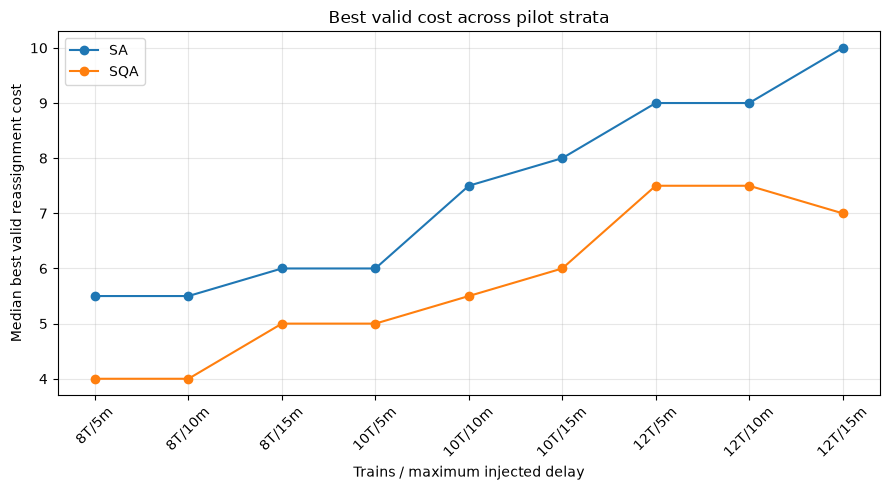

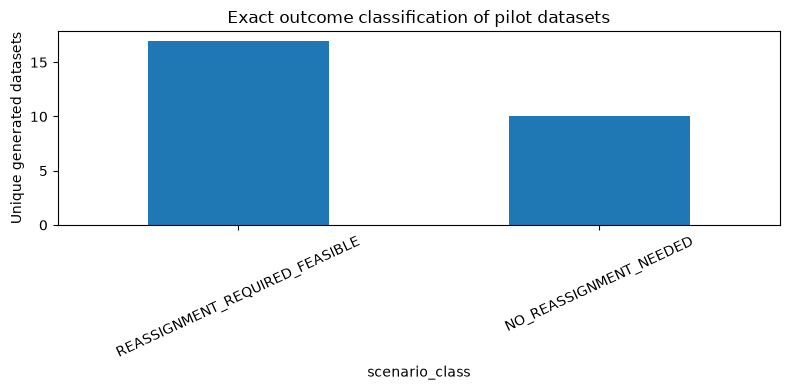

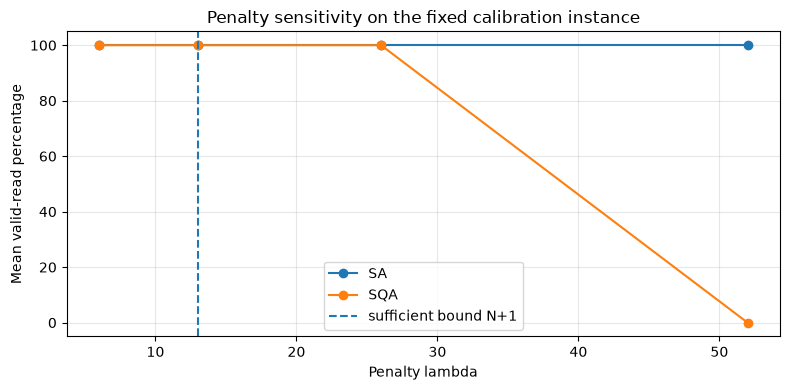

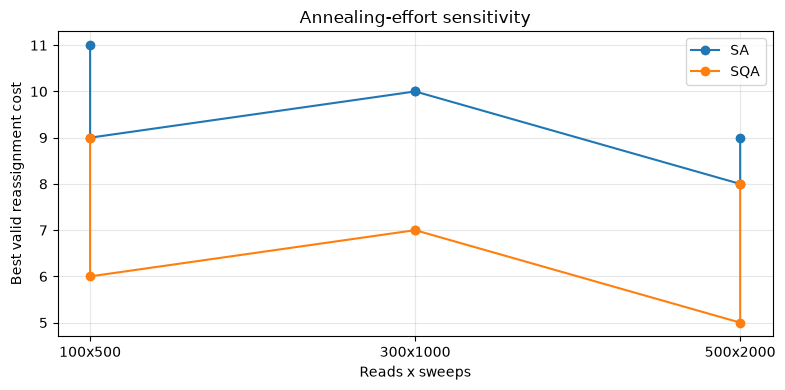

In [16]:
if not pilot_results.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    plot_df = pilot_results.dropna(subset=["best_valid_cost"])
    if not plot_df.empty:
        for alg, group in plot_df.groupby("algorithm"):
            grouped = group.groupby(["n_trains", "delay_max_min"])["best_valid_cost"].median().reset_index()
            labels = [f"{int(r.n_trains)}T/{int(r.delay_max_min)}m" for r in grouped.itertuples()]
            ax.plot(labels, grouped.best_valid_cost, marker="o", label=alg)
        ax.set_ylabel("Median best valid reassignment cost")
        ax.set_xlabel("Trains / maximum injected delay")
        ax.set_title("Best valid cost across pilot strata")
        ax.tick_params(axis="x", rotation=45)
        ax.grid(True, alpha=.3)
        ax.legend()
        plt.tight_layout()
        plt.show()

    class_counts = dataset_diagnostics["scenario_class"].value_counts()
    fig, ax = plt.subplots(figsize=(8, 4))
    class_counts.plot(kind="bar", ax=ax)
    ax.set_ylabel("Unique generated datasets")
    ax.set_title("Exact outcome classification of pilot datasets")
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()

if not penalty_sensitivity_results.empty:
    fig, ax = plt.subplots(figsize=(8, 4))
    for alg, group in penalty_sensitivity_results.groupby("algorithm"):
        stats = group.groupby("penalty_lambda").feasibility_pct.mean()
        ax.plot(stats.index, stats.values, marker="o", label=alg)
    ax.axvline(len(calibration_case["df"]) + 1, linestyle="--", label="sufficient bound N+1")
    ax.set_xlabel("Penalty lambda")
    ax.set_ylabel("Mean valid-read percentage")
    ax.set_title("Penalty sensitivity on the fixed calibration instance")
    ax.grid(True, alpha=.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

if not effort_sensitivity_results.empty:
    fig, ax = plt.subplots(figsize=(8, 4))
    for alg, group in effort_sensitivity_results.groupby("algorithm"):
        xlabels = [f"{int(r.num_reads)}x{int(r.num_sweeps)}" for r in group.itertuples()]
        ax.plot(xlabels, group.best_valid_cost, marker="o", label=alg)
    ax.set_xlabel("Reads x sweeps")
    ax.set_ylabel("Best valid reassignment cost")
    ax.set_title("Annealing-effort sensitivity")
    ax.grid(True, alpha=.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

## 15. Export the pilot and calibration artefacts

Exports are written to the notebook's current working directory. Keep the CSV files with the executed notebook so the experiments are auditable.

In [17]:
def export_frame(frame, filename):
    if frame is None or frame.empty:
        print(f"Skipped empty frame: {filename}")
        return
    frame.to_csv(filename, index=False)
    print(f"Saved {filename} ({len(frame)} rows)")

export_frame(dataset_diagnostics, "jaipur_v3_dataset_diagnostics.csv")
export_frame(generated_train_tables, "jaipur_v3_generated_train_tables.csv")
export_frame(conflict_edge_tables, "jaipur_v3_conflict_edges.csv")
export_frame(pilot_results, "jaipur_v3_sampler_runs.csv")
export_frame(summary_by_scenario, "jaipur_v3_summary_by_scenario.csv")
export_frame(scenario_class_counts, "jaipur_v3_scenario_class_counts.csv")
export_frame(penalty_sensitivity_results, "jaipur_v3_penalty_sensitivity.csv")
export_frame(effort_sensitivity_results, "jaipur_v3_effort_sensitivity.csv")
export_frame(capacity_sensitivity_results, "jaipur_v3_capacity_sensitivity.csv")
export_frame(structural_overload_results, "jaipur_v3_structural_overload_stress.csv")
export_frame(large_28_results, "jaipur_v3_28_train_results.csv")

metadata = {
    "notebook_version": "v3",
    "python_version": sys.version.split()[0],
    "platform": platform.platform(),
    "cpu": platform.processor(),
    "ram_gb": RAM_GB,
    "openjij_version": getattr(oj, "__version__", "unknown"),
    "n_platforms": N_PLATFORMS,
    "clearance_min_assumption": BASE_CLEARANCE_MIN,
    "train_counts": TRAIN_COUNTS,
    "delay_levels_min": DELAY_LEVELS_MIN,
    "dataset_seeds": DATASET_SEEDS,
    "solver_repeats": SOLVER_REPEATS,
    "num_reads": NUM_READS,
    "num_sweeps": NUM_SWEEPS,
    "exact_time_limit_s": EXACT_TIME_LIMIT_S,
    "long_platform_count_main": 4,
    "qubo_identity_check": qubo_check,
}
with open("jaipur_v3_experiment_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
print("Saved jaipur_v3_experiment_metadata.json")

Saved jaipur_v3_dataset_diagnostics.csv (27 rows)
Saved jaipur_v3_generated_train_tables.csv (270 rows)
Saved jaipur_v3_conflict_edges.csv (183 rows)
Saved jaipur_v3_sampler_runs.csv (108 rows)
Saved jaipur_v3_summary_by_scenario.csv (18 rows)
Saved jaipur_v3_scenario_class_counts.csv (12 rows)
Saved jaipur_v3_penalty_sensitivity.csv (16 rows)
Saved jaipur_v3_effort_sensitivity.csv (12 rows)
Skipped empty frame: jaipur_v3_capacity_sensitivity.csv
Saved jaipur_v3_structural_overload_stress.csv (10 rows)
Skipped empty frame: jaipur_v3_28_train_results.csv
Saved jaipur_v3_experiment_metadata.json


## 16. Interpretation and paper-reporting checklist

Before using any result in the paper:

- Report the number of **unique datasets** separately from the number of sampler repeats and reads.
- Report exact `OPTIMAL`, `INFEASIBLE` and `TIMEOUT` counts separately.
- Compute heuristic optimality gaps only when Exact returned `OPTIMAL`.
- Report both per-read feasibility rate and the percentage of exact-feasible instances where the sampler hit the exact optimum.
- Compare SA/SQA on identical generated instances, penalties, reads and sweeps.
- Treat delay maxima and four/five long-platform eligibility as explicit assumptions/sensitivity conditions.
- Do not claim physical quantum annealing or quantum advantage. OpenJij SQA is a classical simulation method.
- Separate sampler runtime from end-to-end workflow runtime.
- Retain all generated cases, including infeasible cases; explain their frequency rather than deleting them.

**Decision gate for the next stage:** proceed to 28 trains only if (a) the QUBO identity test passes, (b) the pilot contains a meaningful number of reassignment-required feasible datasets, (c) penalty sensitivity shows acceptable valid-read rates at the chosen penalty, and (d) increasing reads/sweeps produces interpretable changes in exact-optimum hit rate. If pilot scenarios remain overwhelmingly trivial or infeasible, revise the synthetic timetable assumptions and document that change before any final benchmark.